# Part 3 — Image Transformation (plantCV)
1. Gaussian Blur  2. Mask  3. ROI Objects  4. Analyze Object  5. Pseudolandmarks  6. Color Histogram

When converted to a script, supports CLI flags:
- `./Transformation.py <image_path>` — display transformations for a single image
- `./Transformation.py -src <dir> -dst <dir> -mask` — save transformations for all images in directory
- `./Transformation.py -h` — show help

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import argparse

import cv2
import matplotlib.pyplot as plt
import numpy as np
import plantcv.plantcv as pcv

from src.augmentation import load_rgb
from src.data import CLASSES, DATA_PATH, resolve_images

pcv.params.debug = None

HELP_TEXT = """Usage:
  Transformation.py <image_path>               Show 6 transformations for a single image
  Transformation.py -src <dir> -dst <dir> [-mask]  Save transformations for all images
  Transformation.py -h                         Show this help message

Flags:
  -src <dir>   Source directory containing images
  -dst <dir>   Destination directory for transformed images
  -mask        Apply leaf masking before transformations
  -h           Show this help message"""


def parse_args():
    parser = argparse.ArgumentParser(description="Image Transformation (plantCV)", add_help=False)
    parser.add_argument("-h", "--help", action="store_true", help="Show help message")
    parser.add_argument("-src", type=str, default=None, help="Source directory")
    parser.add_argument("-dst", type=str, default=None, help="Destination directory")
    parser.add_argument("-mask", action="store_true", help="Apply leaf masking")
    parser.add_argument("image", nargs="?", default=None, help="Path to a single image")
    return parser.parse_args()

image shape: (256, 256, 3)


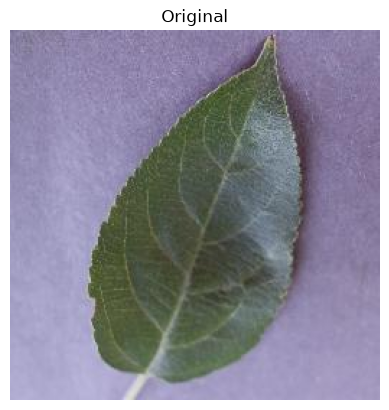

In [2]:
data = resolve_images(DATA_PATH, CLASSES)
sample_path = data["Apple_healthy"][0]
rgb = load_rgb(sample_path)
print("image shape:", rgb.shape)
plt.imshow(rgb)
plt.title("Original")
plt.axis("off")
plt.show()

## T1 — Gaussian Blur

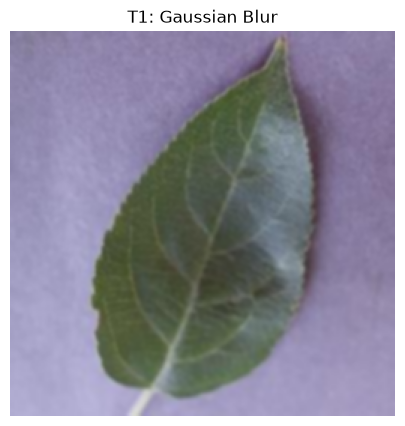

In [3]:
blurred = pcv.gaussian_blur(img=rgb, ksize=(5, 5), sigma_x=0)
plt.figure(figsize=(5, 5))
plt.imshow(blurred)
plt.title("T1: Gaussian Blur")
plt.axis("off")
plt.show()

## T2 — Mask (HSV saturation threshold)

leaf coverage: 86.1%


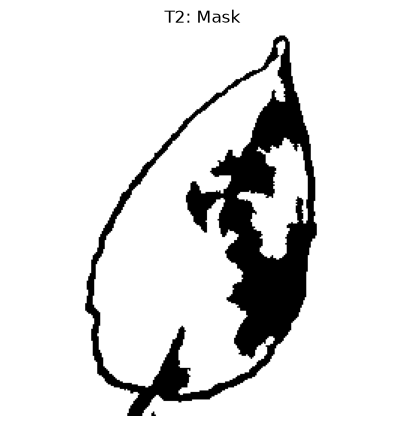

In [4]:
s_channel = pcv.rgb2gray_hsv(rgb_img=blurred, channel="s")
mask = pcv.fill(pcv.threshold.binary(s_channel, threshold=40, object_type="light"), 200)
mask = pcv.fill_holes(bin_img=mask)
print("leaf coverage: %.1f%%" % (100 * mask.mean() / 255))
plt.figure(figsize=(5, 5))
plt.imshow(mask, cmap="gray")
plt.title("T2: Mask")
plt.axis("off")
plt.show()

## T3 — ROI Objects (leaf contour)

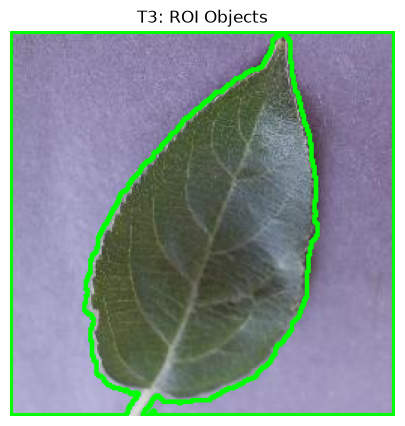

In [5]:
contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
leaf_contour = max(contours, key=cv2.contourArea)
roi_vis = rgb.copy()
cv2.drawContours(roi_vis, [leaf_contour], -1, (0, 255, 0), 2)
plt.figure(figsize=(5, 5))
plt.imshow(roi_vis)
plt.title("T3: ROI Objects")
plt.axis("off")
plt.show()

## T4 — Analyze Object (shape metrics)

In [6]:
lbl, n_lbl = pcv.create_labels(mask=mask)
pcv.outputs.clear()
pcv.analyze.size(img=rgb, labeled_mask=lbl, n_labels=n_lbl)
obs = pcv.outputs.observations["default_1"]
shape = {
    k: obs[k]["value"]
    for k in [
        "area",
        "perimeter",
        "solidity",
        "convex_hull_area",
        "longest_path",
        "ellipse_eccentricity",
        "width",
        "height",
    ]
}
shape["circularity"] = 4 * np.pi * shape["area"] / (shape["perimeter"] ** 2 + 1e-6)
shape["extent"] = shape["area"] / (shape["width"] * shape["height"])
for k, v in shape.items():
    print(f"  {k:20s}  {v:.4f}")

  area                  40700.0000
  perimeter             1716.4823
  solidity              0.6259
  convex_hull_area      65025.0000
  longest_path          355.0127
  ellipse_eccentricity  0.3019
  width                 256.0000
  height                256.0000
  circularity           0.1736
  extent                0.6210


## T5 — Pseudolandmarks

3 groups x 20 points each: (20, 1, 2) (20, 1, 2) (20, 1, 2)


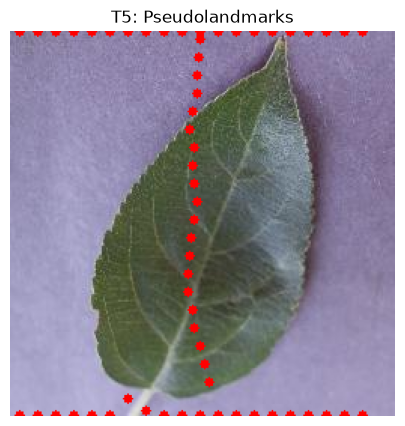

In [7]:
plm = pcv.homology.x_axis_pseudolandmarks(img=rgb, mask=mask, label="leaf")
print("3 groups x 20 points each:", plm[0].shape, plm[1].shape, plm[2].shape)
plm_vis = rgb.copy()
for group in plm:
    for pt in group:
        cv2.circle(plm_vis, (int(pt[0][0]), int(pt[0][1])), 3, (255, 0, 0), -1)
plt.figure(figsize=(5, 5))
plt.imshow(plm_vis)
plt.title("T5: Pseudolandmarks")
plt.axis("off")
plt.show()

## T6 — Color Histogram (HSV inside mask)

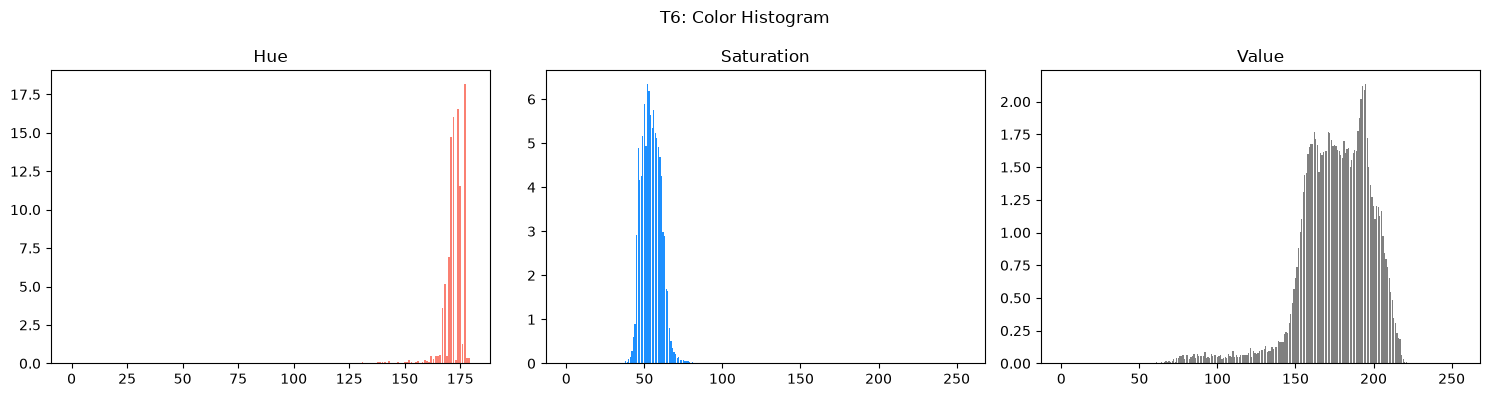

In [8]:
pcv.outputs.clear()
pcv.analyze.color(rgb_img=rgb, labeled_mask=lbl, n_labels=n_lbl, colorspaces="hsv")
obs = pcv.outputs.observations["default_1"]
hue_h = np.array(obs["hue_frequencies"]["value"])
sat_h = np.array(obs["saturation_frequencies"]["value"])
val_h = np.array(obs["value_frequencies"]["value"])
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(range(len(hue_h)), hue_h, color="salmon")
axes[0].set_title("Hue")
axes[1].bar(range(len(sat_h)), sat_h, color="dodgerblue")
axes[1].set_title("Saturation")
axes[2].bar(range(len(val_h)), val_h, color="gray")
axes[2].set_title("Value")
plt.suptitle("T6: Color Histogram")
plt.tight_layout()
plt.show()

## All 6 — grid

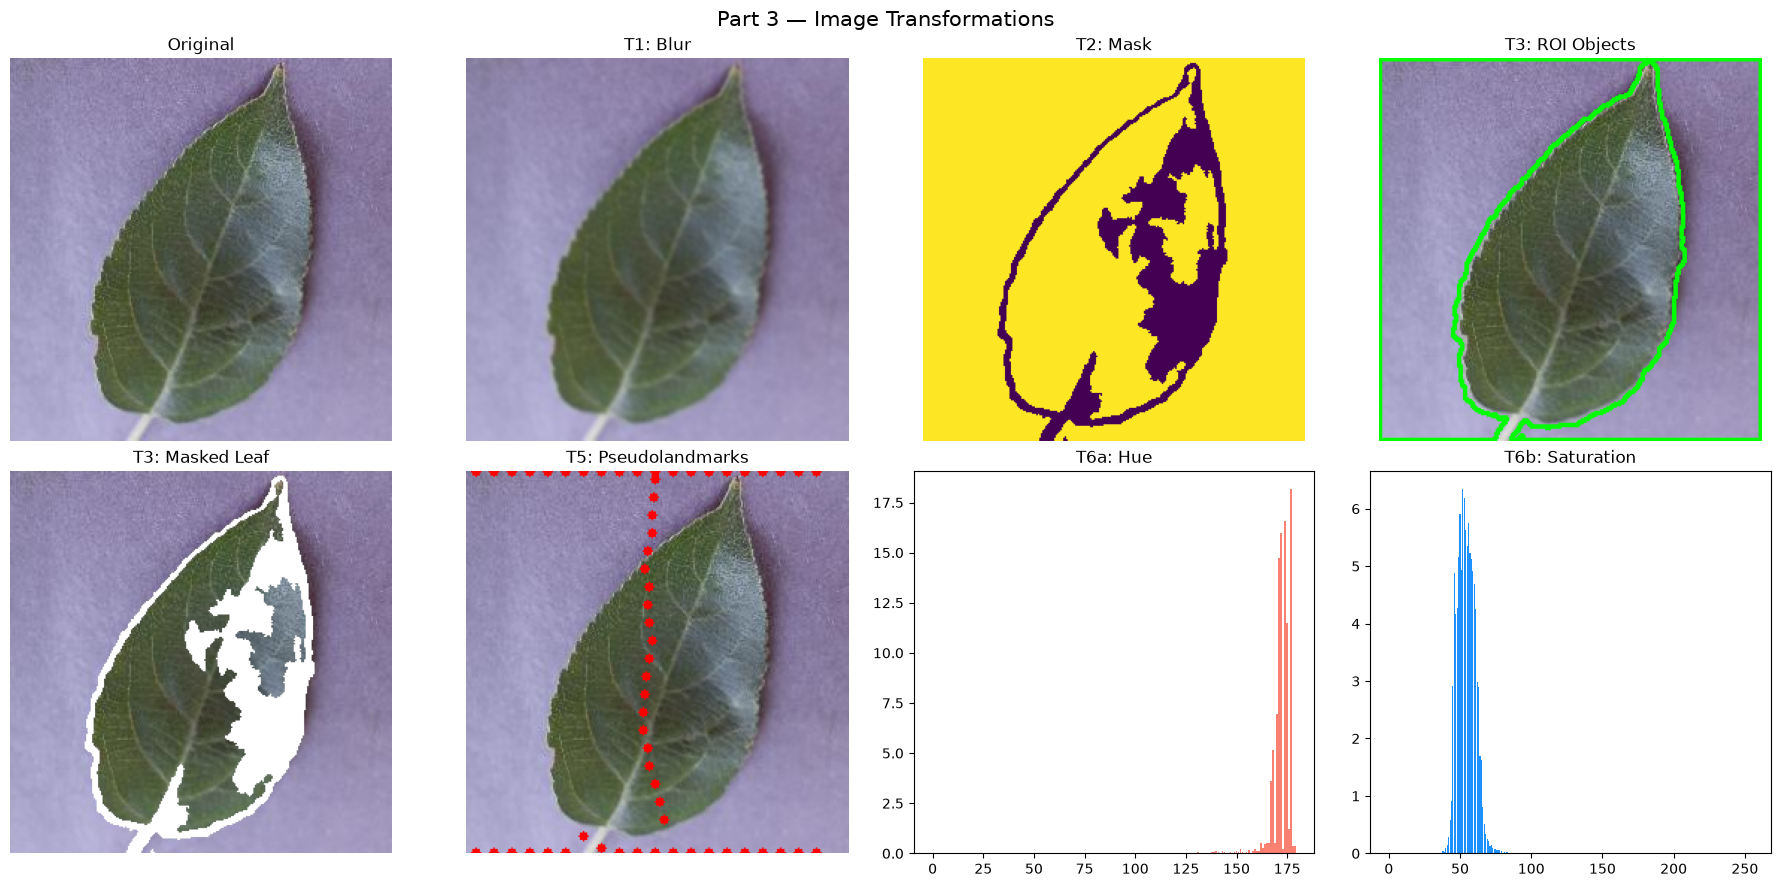

In [9]:
masked = pcv.apply_mask(img=rgb, mask=mask, mask_color="white")
fig, axes = plt.subplots(2, 4, figsize=(18, 9))
panels = [
    (axes[0, 0], rgb, "Original"),
    (axes[0, 1], blurred, "T1: Blur"),
    (axes[0, 2], mask, "T2: Mask"),
    (axes[0, 3], roi_vis, "T3: ROI Objects"),
    (axes[1, 0], masked, "T3: Masked Leaf"),
    (axes[1, 1], plm_vis, "T5: Pseudolandmarks"),
]
for ax, img, title in panels:
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
axes[1, 2].bar(range(len(hue_h)), hue_h, color="salmon")
axes[1, 2].set_title("T6a: Hue")
axes[1, 3].bar(range(len(sat_h)), sat_h, color="dodgerblue")
axes[1, 3].set_title("T6b: Saturation")
plt.suptitle("Part 3 — Image Transformations", fontsize=15)
plt.tight_layout()
plt.show()

## CLI mode (when converted to script)
The cells below handle argument parsing so this notebook can be converted to `Transformation.py`.
In notebook mode, skip to the single-image or directory-processing cell directly.

In [10]:
if __name__ == "__main__" or "ipykernel" in sys.modules:
    try:
        args = parse_args()
    except SystemExit:
        args = argparse.Namespace(help=False, src=None, dst=None, mask=False, image=None)

    if getattr(args, "help", False):
        print(HELP_TEXT)

usage: ipykernel_launcher.py [-h] [-src SRC] [-dst DST] [-mask] [image]
ipykernel_launcher.py: error: unrecognized arguments: --f=/run/user/1000/jupyter/runtime/kernel-v3eaa353579f3323a6e523f13d2afe61ffc7d0f11e.json


In [11]:
# Single image mode: ./Transformation.py <image_path>
if __name__ == "__main__" and getattr(args, "image", None):
    img_path = Path(args.image)
    assert img_path.exists(), f"Image not found: {img_path}"
    rgb = load_rgb(img_path)
    print(f"Processing: {img_path}")
    # Run all 6 transformations and display
    blurred = pcv.gaussian_blur(img=rgb, ksize=(5, 5), sigma_x=0)
    s_channel = pcv.rgb2gray_hsv(rgb_img=blurred, channel="s")
    mask = pcv.fill(pcv.threshold.binary(s_channel, threshold=40, object_type="light"), 200)
    mask = pcv.fill_holes(bin_img=mask)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    leaf_contour = max(contours, key=cv2.contourArea)
    roi_vis = rgb.copy()
    cv2.drawContours(roi_vis, [leaf_contour], -1, (0, 255, 0), 2)
    lbl, n_lbl = pcv.create_labels(mask=mask)
    pcv.outputs.clear()
    pcv.analyze.size(img=rgb, labeled_mask=lbl, n_labels=n_lbl)
    plm = pcv.homology.x_axis_pseudolandmarks(img=rgb, mask=mask, label="leaf")
    plm_vis = rgb.copy()
    for group in plm:
        for pt in group:
            cv2.circle(plm_vis, (int(pt[0][0]), int(pt[0][1])), 3, (255, 0, 0), -1)
    pcv.outputs.clear()
    pcv.analyze.color(rgb_img=rgb, labeled_mask=lbl, n_labels=n_lbl, colorspaces="hsv")
    obs = pcv.outputs.observations["default_1"]
    hue_h = np.array(obs["hue_frequencies"]["value"])
    sat_h = np.array(obs["saturation_frequencies"]["value"])
    masked = pcv.apply_mask(img=rgb, mask=mask, mask_color="white")
    fig, axes = plt.subplots(2, 4, figsize=(18, 9))
    panels = [
        (axes[0, 0], rgb, "Original"),
        (axes[0, 1], blurred, "Gaussian Blur"),
        (axes[0, 2], mask, "Mask"),
        (axes[0, 3], roi_vis, "ROI Objects"),
        (axes[1, 0], masked, "Masked Leaf"),
        (axes[1, 1], plm_vis, "Pseudolandmarks"),
    ]
    for ax, im, title in panels:
        ax.imshow(im)
        ax.set_title(title)
        ax.axis("off")
    axes[1, 2].bar(range(len(hue_h)), hue_h, color="salmon")
    axes[1, 2].set_title("Hue Histogram")
    axes[1, 3].bar(range(len(sat_h)), sat_h, color="dodgerblue")
    axes[1, 3].set_title("Saturation Histogram")
    plt.suptitle(f"Transformations — {img_path.name}", fontsize=14)
    plt.tight_layout()
    plt.show()

In [12]:
# Directory mode: ./Transformation.py -src <dir> -dst <dir> [-mask]
def process_single_image(img_path, dst_dir, apply_mask_flag=False):
    """Apply all 6 transformations to one image and save results."""
    rgb = load_rgb(img_path)
    stem = Path(img_path).stem
    ext = Path(img_path).suffix
    blurred = pcv.gaussian_blur(img=rgb, ksize=(5, 5), sigma_x=0)
    s_channel = pcv.rgb2gray_hsv(rgb_img=blurred, channel="s")
    mask = pcv.fill(pcv.threshold.binary(s_channel, threshold=40, object_type="light"), 200)
    mask = pcv.fill_holes(bin_img=mask)
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    leaf_contour = max(contours, key=cv2.contourArea)
    roi_vis = rgb.copy()
    cv2.drawContours(roi_vis, [leaf_contour], -1, (0, 255, 0), 2)
    lbl, n_lbl = pcv.create_labels(mask=mask)
    pcv.outputs.clear()
    pcv.analyze.size(img=rgb, labeled_mask=lbl, n_labels=n_lbl)
    plm = pcv.homology.x_axis_pseudolandmarks(img=rgb, mask=mask, label="leaf")
    plm_vis = rgb.copy()
    for group in plm:
        for pt in group:
            cv2.circle(plm_vis, (int(pt[0][0]), int(pt[0][1])), 3, (255, 0, 0), -1)
    pcv.outputs.clear()
    pcv.analyze.color(rgb_img=rgb, labeled_mask=lbl, n_labels=n_lbl, colorspaces="hsv")
    masked = pcv.apply_mask(img=rgb, mask=mask, mask_color="white")

    transformations = {
        "Gaussian_Blur": blurred,
        "Mask": mask,
        "ROI_Objects": cv2.cvtColor(roi_vis, cv2.COLOR_RGB2BGR) if len(roi_vis.shape) == 3 else roi_vis,
        "Analyze_Object": cv2.cvtColor(masked, cv2.COLOR_RGB2BGR) if len(masked.shape) == 3 else masked,
        "Pseudolandmarks": cv2.cvtColor(plm_vis, cv2.COLOR_RGB2BGR) if len(plm_vis.shape) == 3 else plm_vis,
    }
    for name, img_arr in transformations.items():
        cv2.imwrite(str(dst_dir / f"{stem}_{name}{ext}"), img_arr)


if __name__ == "__main__" and getattr(args, "src", None):
    src_dir = Path(args.src)
    dst_dir = Path(args.dst) if args.dst else Path("transformed_output")
    dst_dir.mkdir(parents=True, exist_ok=True)
    image_extensions = {".jpg", ".jpeg", ".png", ".JPG", ".JPEG", ".PNG"}
    images = [f for f in src_dir.iterdir() if f.is_file() and f.suffix in image_extensions]
    print(f"Processing {len(images)} images from {src_dir} -> {dst_dir}")
    for img_path in sorted(images):
        try:
            process_single_image(img_path, dst_dir, args.mask)
            print(f"  [OK] {img_path.name}")
        except Exception as e:
            print(f"  [FAIL] {img_path.name}: {e}")
    print(f"Done. Transformed images saved to {dst_dir}")